In [1]:
import os
import pandas as pd 
import numpy as np
import warnings
from pathlib import Path
import json 

import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

from neuron_morphology.swc_io import morphology_from_swc
from morph_utils.visuals import basic_morph_plot
from morph_utils.measurements import leftextent, rightextent #cellwidth, downextent, upextent
from morph_utils.templates import load_layer_template 

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, get_tx_order
from morphology_utils import add_swc_paths

plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


/opt/conda/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [2]:
viewer_type = 'dendrite' #dendrite, axon, both 
species = "human"

In [3]:
# Save root 
viewer_dir = Path('/root/capsule/scratch') / '20260807' /'viewers'
os.makedirs(viewer_dir, exist_ok=True)

viewer_outfile = viewer_dir / 'human_excitatory_supplemental_{}_viewer.pdf'.format(viewer_type)

class_col = 'class_label_Hierarchical'
subclass_col = 'subclass_label_Hierarchical'
cluster_col = 'cluster_label_Hierarchical'

# Data paths
DATA_ROOT = Path('/root/capsule/data')
metadata_path =              DATA_ROOT / 'human'            / 'metadata'   / '20260807' / 'human_metadata.csv'
morpho_data_dend_root =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712'
morpho_data_axon_root =      DATA_ROOT / 'human' / 'morphology' / 'axon'     / '20260715'
layer_aligned_dir =          DATA_ROOT / 'human' / 'morphology' / 'swc'      / '20260625' / 'SWC_LayerAligned'

l23_ttype_rename_file =       DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'

soma_depths_dend_path = morpho_data_dend_root / 'AlignedSomaDepths.csv'
soma_depths_axon_path = morpho_data_axon_root / 'AlignedSomaDepths.csv'


In [4]:
# node types to plot i.e. [soma, axon, basal, apical] 
if viewer_type == 'both': compartment_list=[1,2,3,4]
elif viewer_type == 'axon': compartment_list=[1,2]
elif viewer_type == 'dendrite': compartment_list=[1,3,4] 

ttype_var_name = cluster_col
subclass_var_name = subclass_col
sort_by = [ttype_var_name, 'soma_distance_from_pia'] 
plot_view = 'xy' #'xy', 'yz', or 'both'

if viewer_type == 'dendrite':
    num_rows = 7
else:
    num_rows = 8

#optional 
title = ['structure'] 
title_font_size = [2] 

if plot_view == 'yz': set_side = [True]
elif plot_view == 'both': set_side = [False, True]
else: set_side = [False] #xy or other

Organize

In [5]:
# Load taxonomy dictionaries
with open(l23_ttype_rename_file, "r") as f:
    L23_rename_dict = json.load(f)

# Set some vars
cluster_var = sort_by[0]

# Get layer and color data
layer_info, layer_labels, layer_colors = load_layer_template(species)
color_dict = get_seaad_colors()


#load the cells
if viewer_type == 'dendrite':
    cells = pd.read_csv(soma_depths_dend_path, index_col='specimen_id')

elif viewer_type == 'axon' :
    cells = pd.read_csv(soma_depths_axon_path, index_col='specimen_id')

elif viewer_type == 'both':
    cells_dend = pd.read_csv(soma_depths_dend_path, index_col='specimen_id')
    cells_axon = pd.read_csv(soma_depths_axon_path, index_col='specimen_id')
    cells = cells_dend.loc[cells_dend.index.intersection(cells_axon.index)]
else:
    raise ValueError(f'Unknown viewer_type: {viewer_type}')

metadata = pd.read_csv(metadata_path, index_col='cell_id')
metadata = metadata.merge(cells, how='inner', left_index=True, right_index=True)

# Get layer aligned files
cells['specimen_id'] = cells.index
cells = add_swc_paths(cells, layer_aligned_dir, column_name='SWC_layer_aligned')

#map the normalized depth in pia to the average layer pia/wm values 
avg_pia = layer_info['1']
avg_wm = layer_info['wm']
metadata['depth_from_pia_norm_to_layers'] = metadata['depth_from_pia_norm'].apply(lambda x: x * (avg_wm - avg_pia) + avg_pia if pd.notnull(x) else np.nan)

# Get subclass/ttype order for sorting
ttype_order, subclass_order = get_tx_order() #cells, ttype_var_name)
cells = cells.merge(metadata[[ttype_var_name, subclass_var_name, 'structure']], how='left', left_index=True, right_index=True)
cells[ttype_var_name] = cells[ttype_var_name].replace(L23_rename_dict)
cells[ttype_var_name] = pd.Categorical(cells[ttype_var_name], categories=ttype_order, ordered=True)
cells[subclass_var_name] = pd.Categorical(cells[subclass_var_name], categories=subclass_order, ordered=True)

# Sort cells 
if all(item in list(cells.columns) for item in sort_by): #check if all items in sort_by are column names in cells 
    sorted_cells = cells.sort_values(by=sort_by)
else:
    print('Warning: cannot sort cells. Some value(s) in \'sort_by\' are not column names in input cell csv. Plotting unsorted cells.')
    sorted_cells = cells


Plot

Sps list is 327 long


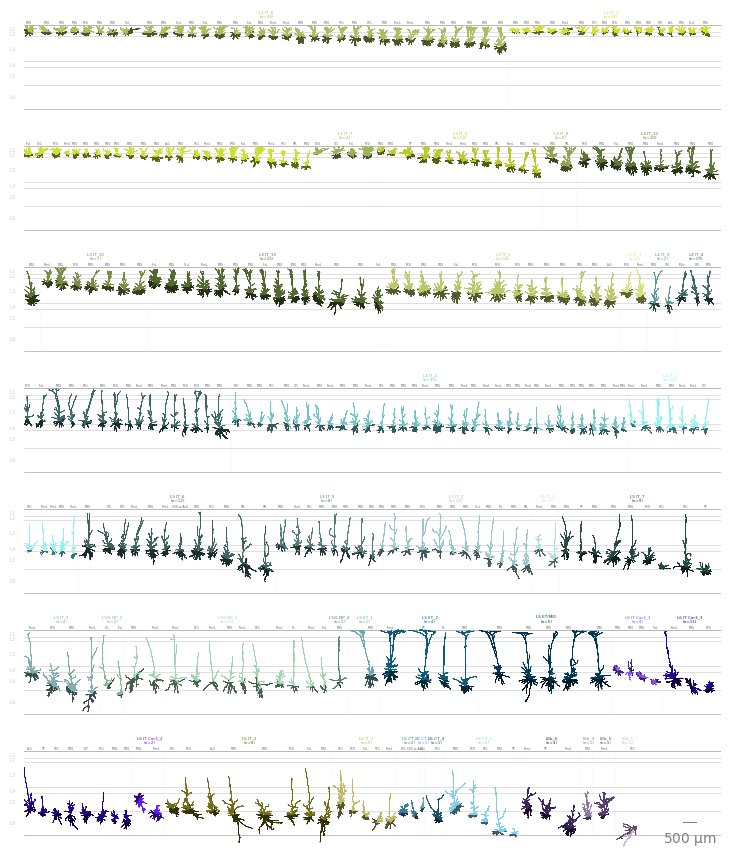

<Figure size 640x480 with 0 Axes>

In [6]:
#make pdf viewer

#formatting vars for tinkering 
group_title_start_height = 300 #900 #starting height for group (e.g., region) title 
group_title_font_size = 4 #font size for group (e.g., region) title 

cell_title_start_height = 250 #700 #starting height for cell title 
cell_title_vertical_space = 200 #150 #how much white space between rows of the cell title
cell_title_view_font_size = 4 #font size for cell 'xy', 'yz' view label

#####

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    sps_list = list(sorted_cells.specimen_id.values)
    sps_list.reverse() #because we pop() off spc, which takes off the last value in the list. Reversing here keeps the plotting order consistent with the csv order.

    clust_id_set = set()
    failed_to_load = []

    print("Sps list is {} long".format(len(sps_list)))

    if viewer_type=='dendrite':
        buffer = 90
    elif viewer_type == 'axon':
        buffer = 80
    else:
        buffer = 80
    with PdfPages(viewer_outfile) as pdf:
        while sps_list != []:
            fig, axes = plt.subplots(nrows=num_rows,ncols=1,figsize=(9,11),sharex=True,sharey=True) 

            title_dict = {} # accumulate info for plotting group (cluster) title centered over the cells 
            
            for ax in axes: 

                ax.axis('off')
                ax.set_xlim(0,25600) 
                lim = 25500
                xloc = 0
                xoffset = 0
                ax.set_anchor('W')
                ax.axhline(0, c="lightgrey",linewidth=0.50)

                # Plot layers with labels 
                for l in layer_info:
                    ax.axhline(-layer_info[l], c=layer_colors[l],linewidth=0.50)
                for l in layer_labels:
                    ax.text(-500,-layer_labels[l], "{}".format(l),verticalalignment='center', horizontalalignment='left',fontsize=4, color='lightgrey') 

                group_start_loc = xloc
                cluster_start_ax = ax
                cluster_start_x = xoffset
                current_cluster_id = None

                while xloc < lim:  # plot as many neurons as fit on this row
                    if not sps_list:
                        break

                    sp = sps_list.pop()

                    # get specimen metadata
                    ttype = sorted_cells.loc[sorted_cells.specimen_id == sp, ttype_var_name].iloc[0]
                    clust_id = sorted_cells.loc[sorted_cells.specimen_id == sp, cluster_var].iloc[0]
                    clust_len = len(sorted_cells.loc[sorted_cells[cluster_var] == clust_id])

                    # cell title
                    sp_title = []
                    if 'title' in locals():
                        for t in title:
                            sp_title.append(str(sorted_cells.loc[sorted_cells.specimen_id == sp, t].iloc[0]))

                    # get plotting colors
                    try:
                        hex_color = color_dict[ttype][1:]
                        contrast_level = 0.45
                        lighter_color_rgb = tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))
                        darker_color_rgb = tuple([int((contrast_level*x)) for x in lighter_color_rgb])
                        grey_hex = '#8f8f8f'
                        dark_hex = '#%02x%02x%02x' % darker_color_rgb
                        hex_color = '#'+hex_color
                        cell_type_colors_dict = {3: dark_hex, 4: hex_color, 2: grey_hex}
                        if compartment_list == [1,2]:
                            cell_type_colors_dict = {3: grey_hex, 4: grey_hex, 2: hex_color}
                    except:
                        cell_type_colors_dict = {1: 'black', 2: "firebrick", 4: "orange", 3: "steelblue"}
                    morph_colors = {k: v for k, v in cell_type_colors_dict.items() if k in compartment_list}

                    # get the morphology
                    swc_pth = sorted_cells.loc[sorted_cells.specimen_id == sp, 'SWC_layer_aligned'].iloc[0]
                    nrn = morphology_from_swc(swc_pth)

                    cell_left = leftextent(nrn, compartment_list)
                    cell_right = rightextent(nrn, compartment_list)

                    # check width limit for this row
                    if xoffset + cell_left + cell_right > lim:
                        # # Cluster split across rows → finalize the previous cluster title on this axis
                        if current_cluster_id is not None:
                            midpoint = cluster_start_x + (xoffset - cluster_start_x) / 2
                            cluster_string = f"{current_cluster_id}\n(n={prev_clust_len})"
                            if not cluster_string in title_dict.keys():
                                title_dict[cluster_string] = {
                                    'ax': cluster_start_ax,
                                    'xloc': midpoint,
                                    'color': current_cluster_color
                                }
                        # push cell back and move to next axis
                        sps_list.append(sp)
                        break

                    # Detect cluster boundary
                    if clust_id != current_cluster_id:
                        # Finish previous cluster if there was one
                        if current_cluster_id is not None:
                            midpoint = cluster_start_x + (xoffset - cluster_start_x) / 2
                            cluster_string = f"{current_cluster_id}\n(n={prev_clust_len})"
                            if not cluster_string in title_dict.keys():
                                title_dict[cluster_string] = {
                                    'ax': cluster_start_ax,
                                    'xloc': midpoint,
                                    'color': current_cluster_color
                                }

                        # Start a new cluster
                        current_cluster_id = clust_id
                        cluster_start_x = xoffset
                        cluster_start_ax = ax
                        current_cluster_color = hex_color
                        prev_clust_len = clust_len

                        vert_x = xoffset - (buffer / 2)
                        ax.plot([vert_x, vert_x], [0, -layer_info['wm']], c='lightgrey', lw=0.1, linestyle='--')

                    xoffset += cell_left

                    # plot cell title
                    y = cell_title_start_height
                    for i, l in enumerate(sp_title):
                        y -= cell_title_vertical_space
                        ax.text(xoffset, y, l, ha='center', fontsize=title_font_size[i], color=color_dict.get(l, 'dimgrey'))

                    # draw the neuron
                    y -= cell_title_vertical_space
                    for s in set_side:
                        basic_morph_plot(
                            nrn, morph_colors=morph_colors, ax=ax, xoffset=xoffset,
                            side=s, scatter_roots=False, scatter_soma=False, plot_soma=False, line_w=0.2
                        )
                        xoffset += cell_right + buffer

                    xloc = xoffset

                # After finishing all cells on this axis, close any open cluster
                if current_cluster_id is not None:
                    midpoint = cluster_start_x + (xoffset - cluster_start_x) / 2
                    cluster_string = f"{current_cluster_id}\n(n={prev_clust_len})"
                    if not cluster_string in title_dict.keys():
                        title_dict[cluster_string] = {
                            'ax': cluster_start_ax,
                            'xloc': midpoint,
                            'color': current_cluster_color
                        }

            
            #add a scale bar 
            scalebar = ScaleBar(1, "um", location='lower right', frameon=False, fixed_value=500, color='grey')
            ax.add_artist(scalebar)

            for title_str, title_specs in title_dict.items():
                    ax = title_specs['ax']
                    ax.text(title_specs['xloc'], group_title_start_height, title_str, horizontalalignment='center', fontsize=3, color=title_specs['color'])  
            
            for ax in axes:
                ax.set_aspect("equal")
            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600)
    plt.show()
    plt.clf()
    print()


Layer 6 Apical PC Dendrite Viewer

In [16]:
# Load the feature data with apical PC values
raw_features_path = morpho_data_dend_root / 'RawFeatureWide.csv'
raw_features = pd.read_csv(raw_features_path, index_col='specimen_id')

pc_col = 'apical_dendrite_depth_pc_3'

# Load metadata for Layer 6 cells
l6_metadata = metadata[metadata[subclass_col].str.contains('L6', na=False)].copy()

# Merge with raw features to get apical PC values
l6_cells = l6_metadata.merge(raw_features[[pc_col]], 
                              left_index=True, right_index=True, how='inner')

# Merge with soma depths to get SWC paths
l6_cells = l6_cells.merge(cells[['SWC_layer_aligned']], 
                          left_index=True, right_index=True, how='inner')

# Sort by apical PC 0
l6_cells = l6_cells.sort_values(pc_col)

print(f"Found {len(l6_cells)} Layer 6 cells")
print(f"Apical PC 0 range: {l6_cells[pc_col].min():.2f} to {l6_cells[pc_col].max():.2f}")
print(f"Supertypes: {l6_cells[subclass_col].unique()}")

Found 45 Layer 6 cells
Apical PC 0 range: -128.31 to 496.76
Supertypes: ['L6b' 'L6 IT Car3' 'L6 IT' 'L6 CT']


Total width needed: 27432 units
Figure width: 12.1 inches


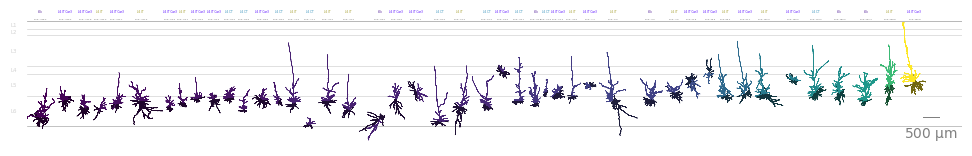

Saved to: /root/capsule/scratch/20260807/viewers/L6_dendrite_viewer_by_apical_dendrite_depth_pc_3.pdf


<Figure size 640x480 with 0 Axes>

In [17]:
# Create colormap for apical PC values
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Normalize apical PC values for coloring
pc_min = l6_cells[pc_col].min()
pc_max = l6_cells[pc_col].max()
norm = Normalize(vmin=pc_min, vmax=pc_max)
cmap = plt.cm.viridis  # or any other colormap

# Output file
l6_viewer_outfile = viewer_dir / f'L6_dendrite_viewer_by_{pc_col}.pdf'

# Compartments for dendrites only (basal=3, apical=4)
l6_compartment_list = [3, 4]

# Buffer between cells
buffer = 90

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    
    # First pass: calculate total width needed
    total_width = 0
    cell_widths = []
    
    for specimen_id, row in l6_cells.iterrows():
        swc_pth = row['SWC_layer_aligned']
        nrn = morphology_from_swc(swc_pth)
        cell_left = leftextent(nrn, l6_compartment_list)
        cell_right = rightextent(nrn, l6_compartment_list)
        cell_widths.append((cell_left, cell_right))
        total_width += cell_left + cell_right + buffer
    
    # Add some padding
    total_width += 1000
    
    # Calculate appropriate figure width (scale from default 11 inches)
    # Standard width handles ~25000 units, scale proportionally
    fig_width = max(11, (total_width / 25000) * 11)
    
    print(f"Total width needed: {total_width:.0f} units")
    print(f"Figure width: {fig_width:.1f} inches")
    
    with PdfPages(l6_viewer_outfile) as pdf:
        # Single row figure with dynamic width
        fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(fig_width, 9))
        
        ax.axis('off')
        ax.set_xlim(0, total_width)
        ax.set_anchor('W')
        ax.axhline(0, c="lightgrey", linewidth=0.50)
        
        # Plot layers with labels
        for l in layer_info:
            ax.axhline(-layer_info[l], c=layer_colors[l], linewidth=0.50)
        for l in layer_labels:
            ax.text(-500, -layer_labels[l], "{}".format(l), 
                   verticalalignment='center', horizontalalignment='left', 
                   fontsize=4, color='lightgrey')
        
        xoffset = 0
        
        for idx, ((specimen_id, row), (cell_left, cell_right)) in enumerate(zip(l6_cells.iterrows(), cell_widths)):
            # Get apical PC value for coloring
            pc_value = row[pc_col]
            color_value = cmap(norm(pc_value))
            hex_color = '#{:02x}{:02x}{:02x}'.format(
                int(color_value[0]*255), 
                int(color_value[1]*255), 
                int(color_value[2]*255)
            )
            
            # Create darker version for basal dendrites
            contrast_level = 0.45
            lighter_color_rgb = (int(color_value[0]*255), 
                               int(color_value[1]*255), 
                               int(color_value[2]*255))
            darker_color_rgb = tuple([int((contrast_level*x)) for x in lighter_color_rgb])
            dark_hex = '#%02x%02x%02x' % darker_color_rgb
            
            # Color dict: basal (3) = darker, apical (4) = lighter
            morph_colors = {3: dark_hex, 4: hex_color}
            
            # Get supertype and its color
            supertype = row[subclass_col]
            supertype_color = color_dict.get(supertype, 'dimgrey')
            
            # Load morphology
            swc_pth = row['SWC_layer_aligned']
            nrn = morphology_from_swc(swc_pth)
            
            xoffset += cell_left
            
            # Plot supertype title in supertype color
            ax.text(xoffset, 250, supertype, ha='center', fontsize=2, color=supertype_color)
            
            # Plot apical PC value
            ax.text(xoffset, 50, f'PC0: {pc_value:.1f}', ha='center', fontsize=1.5, color='dimgrey')
            
            # Draw the neuron dendrites
            basic_morph_plot(
                nrn, morph_colors=morph_colors, ax=ax, xoffset=xoffset,
                side=False, scatter_roots=False, scatter_soma=False, 
                plot_soma=False, line_w=0.2
            )
            
            xoffset += cell_right + buffer
        
        # Add scale bar
        scalebar = ScaleBar(1, "um", location='lower right', frameon=False, 
                          fixed_value=500, color='grey')
        ax.add_artist(scalebar)
        
        ax.set_aspect("equal")
        pdf.savefig(dpi=600)
        
plt.show()
plt.clf()
print(f"Saved to: {l6_viewer_outfile}")